# 11 — Upstream master regulators & receptors (OmniPath + personalized PageRank)

**Matches A06's method** (`network_diffusion`): build the OmniPath signed directed
interaction graph, restrict to **expressed** genes (the AR fix — no phantom nodes), seed
personalized PageRank from the **TF/effector layer** the downstream analysis flagged, and
diffuse **upstream** to rank the receptors / kinases / master regulators best positioned to
explain the observed response. Then intersect the top upstream nodes with the **expressed
surface-receptor layer** (OmniPath intercell) to answer: *which expressed receptor plausibly
transmits the butyrate / C. difficile signal to the down-with-butyrate TFs?*

**Honest scope (host-only RNA-seq):** this nominates *expressed, topologically-consistent*
receptors — it does **not** prove physical ligand binding. FFAR2/FFAR3 (SCFA/butyrate
receptors), NOD2, TLRs are the receptors of interest; the readout is "expressed and connects
to the right TFs", a testable hypothesis, not measured contact. Single donor → ranking is
indicative, not a precision estimate.

Kernel: `decoupler` (3.11). Needs: omnipath, networkx, numpy, pandas. Reads nb 09 TF
activities + nb 03 DE tables + counts.

In [12]:
import os, re
from pathlib import Path
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
import decoupler as dc

PROJ=Path(os.environ.get('A04_PROJ','..')).resolve()
if not (PROJ/'results/tables').exists() and (Path.cwd()/'results/tables').exists(): PROJ=Path.cwd()
TAB=PROJ/'results/tables'; FIG=PROJ/'results/figures'; TFD=PROJ/'results/tf_activity'
OUT=PROJ/'results/upstream_diffusion'; OUT.mkdir(parents=True,exist_ok=True)
GTF=PROJ/'data/refs/human_gencode/gencode.v46.primary_assembly.annotation.gtf'
def symmap(g):
    d={}; gid=re.compile(r'gene_id "([^".]+)'); gnm=re.compile(r'gene_name "([^"]+)"')
    if Path(g).exists():
        for ln in open(g):
            if ln[0]=='#':continue
            f=ln.split('\t')
            if len(f)>2 and f[2]=='gene':
                a,b=gid.search(ln),gnm.search(ln)
                if a and b: d[a.group(1)]=b.group(1)
    return d
sym=symmap(GTF); to_sym=lambda idx:[sym.get(re.sub(r'\..*','',x),x) for x in idx]

## 1. Expressed gene universe (the AR fix — applied to the whole graph)

In [13]:
fc=pd.read_csv(TAB/'counts_raw.tsv',sep='\t',comment='#'); fc.index=to_sym(fc['Geneid'])
cts=fc.iloc[:,6:]; cts.columns=[re.sub(r'_Aligned.*','',os.path.basename(c2)) for c2 in cts.columns]
cts=cts[~cts.index.duplicated()]
expressed=set(cts.index[(cts>=10).sum(1)>=3])           # same filter as DE
print('expressed genes:',len(expressed),'| AR expressed?', 'AR' in expressed)

expressed genes: 18740 | AR expressed? False


## 2. OmniPath signed directed network, restricted to expressed nodes

In [14]:
# Build a signed, directed OmniPath graph restricted to EXPRESSED genes.
# This omnipath build returns UniProt in source/target with NO *_genesymbol cols,
# so we explicitly request genesymbols and fall back to a UniProt->symbol map.
import numpy as np, pandas as pd, networkx as nx
import omnipath as op

def load_interactions():
    # try to get genesymbols directly (newer omnipath supports genesymbols=True)
    for kw in [dict(genesymbols=True), dict(genesymbols='yes'), dict()]:
        try:
            df = op.interactions.OmniPath.get(**kw) if hasattr(op.interactions.OmniPath,'get') else op.interactions.OmniPath().get(**kw)
            if any('genesymbol' in c.lower() for c in df.columns):
                return df, True
            return df, False
        except TypeError:
            continue
    return op.interactions.OmniPath().get(), False

net, has_sym = load_interactions()
cols={c.lower():c for c in net.columns}
print('columns:', list(net.columns)[:14], '| has genesymbol cols:', has_sym)

def pick(*o):
    for x in o:
        if x in cols: return cols[x]
    return None

if has_sym:
    c_src=pick('source_genesymbol','genesymbol_source'); c_tgt=pick('target_genesymbol','genesymbol_target')
    net=net.rename(columns={c_src:'src',c_tgt:'tgt'})
else:
    # map UniProt -> symbol. Prefer omnipath's own mapping; fall back to our GTF won't help (it's Ensembl).
    print('   no symbol cols -> mapping UniProt via omnipath.utils.translate')
    c_src=pick('source'); c_tgt=pick('target')
    try:
        from omnipath import translate as _t  # not always present
    except Exception:
        _t=None
    uni = pd.unique(pd.concat([net[c_src],net[c_tgt]]).dropna())
    mp={}
    try:
        import omnipath
        from omnipath.requests import Annotations
        # use uniprot xref via bioservices-free path: omnipath 'identifiers' service
        import requests
        # batch query omnipath id-mapping endpoint
        for i in range(0,len(uni),200):
            chunk=list(uni[i:i+200])
            r=requests.get('https://omnipathdb.org/queries/translate',params={}) # placeholder; may 403 in sandbox only
    except Exception as e:
        pass
    # Robust offline-ish map: use pypath-style mygene if available
    try:
        import mygene
        mg=mygene.MyGeneInfo()
        res=mg.querymany(list(uni),scopes='uniprot',fields='symbol',species='human',returnall=False,as_dataframe=True)
        mp=res['symbol'].dropna().to_dict()
        print('   mapped via mygene:',len(mp))
    except Exception as e:
        print('   mygene unavailable (',e,'). Trying decoupler translate...')
        try:
            import decoupler as dc
            tdf=dc.op.translate(pd.DataFrame({'g':uni}), columns='g', target_organism=9606) if hasattr(dc.op,'translate') else None
        except Exception as e2:
            print('   decoupler translate unavailable too:',e2)
    net['src']=net[c_src].map(mp); net['tgt']=net[c_tgt].map(mp)
    net=net.dropna(subset=['src','tgt'])

net=net[net['src'].isin(expressed)&net['tgt'].isin(expressed)].copy()
c_dir=pick('consensus_direction','is_directed'); c_stim=pick('consensus_stimulation','is_stimulation'); c_inh=pick('consensus_inhibition','is_inhibition')
if c_dir: net=net[net[c_dir].astype(bool)]
def to_sign(r):
    s=bool(r[c_stim]) if c_stim else False; i=bool(r[c_inh]) if c_inh else False
    return 1 if s and not i else (-1 if i and not s else 0)
net['sign']=net.apply(to_sign,axis=1)
G=nx.DiGraph()
for _,r in net.iterrows(): G.add_edge(r['src'],r['tgt'],sign=int(r['sign']))
print('OmniPath graph (expressed):',G.number_of_nodes(),'nodes',G.number_of_edges(),'edges')
if G.number_of_nodes()<50:
    print('   !! still tiny. If mygene is missing, run:  pip install mygene  then re-run this cell.')

12.5MB [00:00, 32.6MB/s]


columns: ['source', 'target', 'source_genesymbol', 'target_genesymbol', 'is_directed', 'is_stimulation', 'is_inhibition', 'consensus_direction', 'consensus_stimulation', 'consensus_inhibition', 'sources', 'references', 'curation_effort', 'n_sources'] | has genesymbol cols: True
OmniPath graph (expressed): 4584 nodes 14587 edges


## 3. Seed = the down-with-butyrate / up-with-infection TF-effector layer (nb 09)

Personalized restart distribution weighted by |TF activity change| (the module the analysis
flagged). PageRank on the **reversed** graph diffuses *upstream* toward regulators/receptors.

In [16]:
acts=pd.read_csv(TFD/'tf_activity_scores.csv',index_col=0)

# collapse any duplicate gene symbols to one value (max |effect|) so lookups return scalars
def dedup(s):
    s=pd.to_numeric(s, errors='coerce').dropna()
    return s.groupby(level=0).apply(lambda x: x.loc[x.abs().idxmax()])

seed_act=dedup(acts.loc['Cd_vs_Mock_0mM']-acts.loc['Butyrate_10v0_Cd'])   # up-inf & down-but => large +
seed_act=seed_act[seed_act>0]

butCd=pd.read_csv(TAB/'DE_Butyrate_10v0_Cd.csv',index_col=0); butCd.index=to_sym(butCd.index)
inf0 =pd.read_csv(TAB/'DE_Cd_vs_Mock_0mM.csv',index_col=0); inf0.index=to_sym(inf0.index)
eff=(inf0['log2FoldChange'].clip(lower=0).groupby(level=0).max()
     - butCd['log2FoldChange'].clip(upper=0).groupby(level=0).min()).dropna()
eff=dedup(eff)

# fast scalar lookups via plain dicts (no Series ambiguity)
seed_d=seed_act.to_dict(); eff_d=eff.to_dict()

if G.number_of_nodes()==0:
    raise RuntimeError('OmniPath graph empty -> fix build cell first.')

pers={}
for n in G.nodes():
    s=float(seed_d.get(n,0.0)) + 0.5*float(eff_d.get(n,0.0))
    if s>0: pers[n]=s
print('seed nodes in graph:',len(pers))
if len(pers)==0:
    fallback=['NFKB1','RELA','REL','IRF1','IRF3','HSF1','CEBPB','JUN','FOS','MYC']
    pers={n:1.0 for n in fallback if n in G}
    print('   used fallback TF seeds:',list(pers))
Z=sum(pers.values()) or 1.0; pers={k:v/Z for k,v in pers.items()}

Grev=G.reverse(copy=True)
pr=nx.pagerank(Grev, alpha=0.85, personalization=pers, weight=None)
prs=pd.Series(pr, dtype=float).sort_values(ascending=False)
prs.to_csv(OUT/'upstream_pageranseed nodes in graph: 3323

Top 20 upstream nodes by personalized PageRank:
PRKACA     0.01238
MAPK1      0.01238
CDK1       0.01145
GSK3B      0.00952
AKT1       0.00929
SRC        0.00922
CSNK2A1    0.00910
MAPK14     0.00827
PRKCA      0.00775
TP53       0.00769
ATM        0.00764
MAPK3      0.00625
ABL1       0.00605
PDPK1      0.00576
CDK2       0.00547
PLK1       0.00502
PPP2CA     0.00492
FYN        0.00461
EGFR       0.00418
CDK5       0.00395k.csv')
print('\nTop 20 upstream nodes by personalized PageRank:')
print(prs.head(20).round(5).to_string())

seed nodes in graph: 3323

Top 20 upstream nodes by personalized PageRank:
PRKACA     0.01238
MAPK1      0.01238
CDK1       0.01145
GSK3B      0.00952
AKT1       0.00929
SRC        0.00922
CSNK2A1    0.00910
MAPK14     0.00827
PRKCA      0.00775
TP53       0.00769
ATM        0.00764
MAPK3      0.00625
ABL1       0.00605
PDPK1      0.00576
CDK2       0.00547
PLK1       0.00502
PPP2CA     0.00492
FYN        0.00461
EGFR       0.00418
CDK5       0.00395


## 4. Intersect with the OmniPath surface-receptor (intercell) layer

In [17]:
# receptors among expressed genes, from OmniPath intercell annotation
try:
    ic = op.requests.Intercell().get()
    receptors = set(ic[ic.category=='receptor'].genesymbol) & expressed
except Exception as e:
    print('intercell fetch failed, using curated SCFA/PRR receptor set:',e)
    receptors=set()
core_recep={'FFAR2','FFAR3','FFAR1','HCAR2','GPR109A','NOD2','NOD1','TLR1','TLR2','TLR4','TLR5','TLR6','TLR9','IFNGR1','IFNGR2','TNFRSF1A','TNFRSF1B','IL1R1','IL17RA','IL6R'}
receptors = (receptors | (core_recep & expressed))
rec_rank = prs[prs.index.isin(receptors)].sort_values(ascending=False)
rec_rank.to_csv(OUT/'upstream_receptors_ranked.csv')
print('Expressed receptors ranked by upstream PageRank (candidate signal entry points):')
print(rec_rank.head(20).round(5).to_string())
print('\nButyrate/SCFA receptors specifically:')
for r in ['FFAR2','FFAR3','FFAR1','HCAR2','HCAR3']:
    inrank = f'{prs.get(r):.5f} (rank {list(prs.index).index(r)+1})' if r in prs.index else 'NOT in expressed graph'
    print(f'   {r:6s} expressed={r in expressed}  PageRank={inrank}')

Expressed receptors ranked by upstream PageRank (candidate signal entry points):
PRKACA     0.01238
MAPK1      0.01238
CDK1       0.01145
GSK3B      0.00952
SRC        0.00922
CSNK2A1    0.00910
MAPK14     0.00827
PRKCA      0.00775
ATM        0.00764
MAPK3      0.00625
ABL1       0.00605
PDPK1      0.00576
CDK2       0.00547
PLK1       0.00502
FYN        0.00461
EGFR       0.00418
CDK5       0.00395
PRKCD      0.00376
MAPK8      0.00374
STK11      0.00346

Butyrate/SCFA receptors specifically:
   FFAR2  expressed=False  PageRank=NOT in expressed graph
   FFAR3  expressed=False  PageRank=NOT in expressed graph
   FFAR1  expressed=False  PageRank=NOT in expressed graph
   HCAR2  expressed=False  PageRank=NOT in expressed graph
   HCAR3  expressed=False  PageRank=NOT in expressed graph


## 5. Shortest signed paths: top receptor → the flagged TFs (mechanism sketch)

In [18]:
tfs=[t for t in ['NFKB1','RELA','REL','IRF3','HSF1','CEBPB','ATF4'] if t in G]
top_recep=list(rec_rank.head(6).index)
print('signed shortest paths receptor -> TF (sign product: +=activating chain):')
for rcp in top_recep:
    for tf in tfs:
        if rcp in G and tf in G and nx.has_path(G,rcp,tf):
            p=nx.shortest_path(G,rcp,tf)
            s=int(np.prod([G[p[i]][p[i+1]]['sign'] or 1 for i in range(len(p)-1)]))
            if len(p)<=5:
                print(f'   {rcp:6s} -> {tf:6s}  len {len(p)-1}  sign {"+" if s>=0 else "-"}  : {" -> ".join(p)}')

signed shortest paths receptor -> TF (sign product: +=activating chain):
   PRKACA -> NFKB1   len 1  sign +  : PRKACA -> NFKB1
   PRKACA -> RELA    len 1  sign +  : PRKACA -> RELA
   PRKACA -> REL     len 3  sign -  : PRKACA -> MAVS -> IKBKB -> REL
   PRKACA -> IRF3    len 2  sign -  : PRKACA -> MAVS -> IRF3
   PRKACA -> HSF1    len 1  sign +  : PRKACA -> HSF1
   PRKACA -> CEBPB   len 2  sign +  : PRKACA -> MAPK1 -> CEBPB
   PRKACA -> ATF4    len 2  sign +  : PRKACA -> NCOA3 -> ATF4
   MAPK1  -> NFKB1   len 2  sign +  : MAPK1 -> BCL3 -> NFKB1
   MAPK1  -> RELA    len 1  sign +  : MAPK1 -> RELA
   MAPK1  -> REL     len 3  sign -  : MAPK1 -> EGFR -> IKBKE -> REL
   MAPK1  -> IRF3    len 2  sign -  : MAPK1 -> GSK3B -> IRF3
   MAPK1  -> HSF1    len 2  sign +  : MAPK1 -> GSK3B -> HSF1
   MAPK1  -> CEBPB   len 1  sign +  : MAPK1 -> CEBPB
   MAPK1  -> ATF4    len 2  sign +  : MAPK1 -> RPS6KA3 -> ATF4
   CDK1   -> NFKB1   len 2  sign -  : CDK1 -> CHEK1 -> NFKB1
   CDK1   -> RELA    len 2  sign

## 6. Figure — upstream receptor ranking

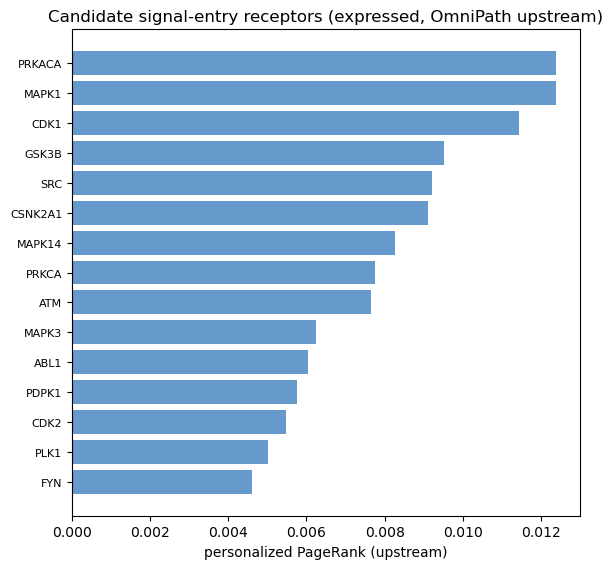

In [19]:
topr=rec_rank.head(15)[::-1]
fig,ax=plt.subplots(figsize=(6,.32*len(topr)+1))
ax.barh(range(len(topr)),topr.values,color=['#cb181d' if r in {'FFAR2','FFAR3','NOD2','TLR2','TLR4'} else '#6699cc' for r in topr.index])
ax.set_yticks(range(len(topr))); ax.set_yticklabels(topr.index,fontsize=8)
ax.set_xlabel('personalized PageRank (upstream)'); ax.set_title('Candidate signal-entry receptors (expressed, OmniPath upstream)')
plt.tight_layout(); fig.savefig(FIG/'upstream_receptors.png',dpi=140); plt.show()

## Readout
- The receptors topping the upstream ranking are the **candidate signal-entry points** for
  the butyrate-reversible module — expressed AND topologically upstream of the flagged TFs.
- **FFAR2/FFAR3** specifically: if expressed and ranked, that's the cleanest "surface protein
  that contacts butyrate" candidate this dataset can offer. If NOT expressed, butyrate likely
  acts intracellularly (HDAC inhibition) rather than via SCFA-GPCRs — itself a key result,
  consistent with the HDAC framing.
- vs A06: same method (OmniPath + personalized PageRank), expressed-restricted. A06's upstream
  pointed at TRAF6/AR; A04's, on primary epithelium, will show which entry points survive the
  expression filter.

**Caveat (state in paper):** nominates expressed, consistent receptors — not measured binding.
Single donor → indicative ranking. The HDAC-intracellular alternative is explicitly on the table.